In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

cv_f1 = {
    "Random Forest (MFCC)": [0.276, 0.229, 0.306, 0.374, 0.290],
    "SVM (MFCC)":           [0.577, 0.428, 0.519, 0.713, 0.538],
    "YAMNet + network":     [0.838, 0.814, 0.815, 0.671, 0.857],
}
summary = pd.DataFrame({
    "Model": list(cv_f1),
    "Macro F1 mean": [np.mean(v) for v in cv_f1.values()],
    "Macro F1 std":  [np.std(v) for v in cv_f1.values()],
}).round(3)
print(summary.to_string(index=False))

               Model  Macro F1 mean  Macro F1 std
Random Forest (MFCC)          0.295         0.047
          SVM (MFCC)          0.555         0.093
    YAMNet + network          0.799         0.066


          class  SVM recall  YAMNet recall  YAMNet precision
       car_horn        0.38           0.90              0.69
    clock_alarm        0.32           0.88              0.83
    crying_baby        0.42           0.92              0.86
            dog        0.45           0.90              0.38
door_wood_knock        0.88           0.78              0.67
 glass_breaking        0.82           0.85              0.47
          siren        0.30           0.95              0.88


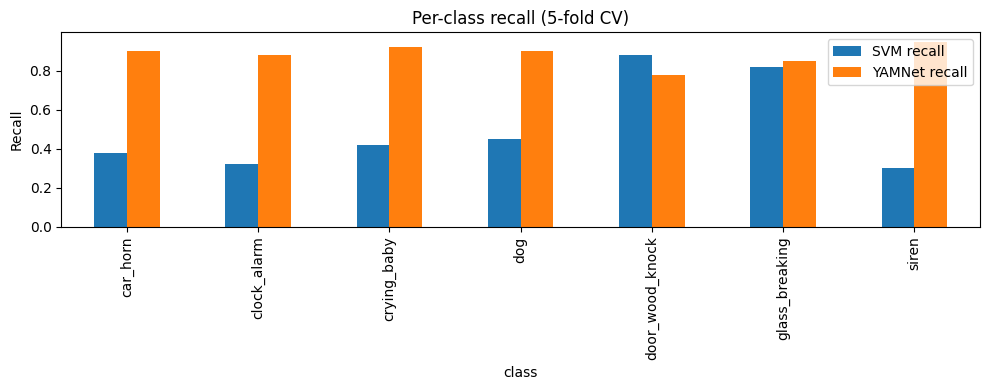

In [2]:
per_class = pd.DataFrame({
    "class": ["car_horn","clock_alarm","crying_baby","dog",
              "door_wood_knock","glass_breaking","siren"],
    "SVM recall":    [0.38, 0.32, 0.42, 0.45, 0.88, 0.82, 0.30],
    "YAMNet recall": [0.90, 0.88, 0.92, 0.90, 0.78, 0.85, 0.95],
    "YAMNet precision": [0.69, 0.83, 0.86, 0.38, 0.67, 0.47, 0.88],
})
print(per_class.to_string(index=False))

per_class.set_index("class")[["SVM recall","YAMNet recall"]].plot.bar(figsize=(10,4))
plt.ylabel("Recall"); plt.title("Per-class recall (5-fold CV)")
plt.tight_layout(); plt.show()

In [3]:
alerts = pd.DataFrame({
    "Model": ["SVM (MFCC)", "YAMNet + network"],
    "Targets caught (of 280)": [143, 247],
    "Background false alerts (of 1720)": [104, 132],
})
print(alerts.to_string(index=False))

           Model  Targets caught (of 280)  Background false alerts (of 1720)
      SVM (MFCC)                      143                                104
YAMNet + network                      247                                132


## Selected model
YAMNet embeddings (mean + max over windows, 2048 features) + small Keras
classifier. Per-class thresholds from out-of-fold probabilities.

Why: macro F1 0.799 +/- 0.066 vs 0.555 +/- 0.093 (SVM) in 5-fold CV, and
recall on all 7 target sounds of 0.78-0.95 (SVM: 0.30-0.88).
Cost: more false alerts on background (132/1720 vs 104/1720); YAMNet
trained on 3 folds per round vs 4 for the SVM.
Caveats: thresholds were chosen on the same CV predictions they were
measured on; background class is ESC-50 only (no speech/TV/music).